In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/simuteh-1004"

DATA = os.path.join(BASE, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
BERSIH = os.path.join(DATA, "bersih")
MASK_DAUN = os.path.join(DATA, "mask_daun")
MASK_BERCAK = os.path.join(DATA, "mask_bercak")
HASIL = os.path.join(BASE, "hasil")

os.makedirs(HASIL, exist_ok=True)

sys.path.insert(0, os.path.join(BASE, "src"))

from utils_cv import baca, tampil, kontras_bercak, statistik

label = pd.read_csv(os.path.join(DATA, "label.csv"))

print("Jumlah data:", len(label))
print(label.head())

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah data: 60
     nama_file  kelas  kondisi_cahaya  persen_bercak
0  teh_001.png  sehat          normal            0.0
1  teh_002.png  sehat           gelap            0.0
2  teh_003.png  sehat          terang            0.0
3  teh_004.png  sehat  kontras_rendah            0.0
4  teh_005.png  sehat        bayangan            0.0


Nama citra: teh_045.png
Ukuran citra: (480, 640, 3)


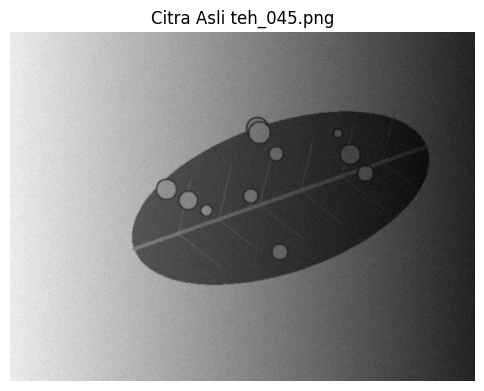

In [2]:
nama = "teh_045.png"

path = os.path.join(CITRA, nama)

img = baca(path)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("Nama citra:", nama)
print("Ukuran citra:", img.shape)

plt.figure(figsize=(6, 5))
plt.imshow(gray, cmap="gray")
plt.title("Citra Asli " + nama)
plt.axis("off")
plt.show()

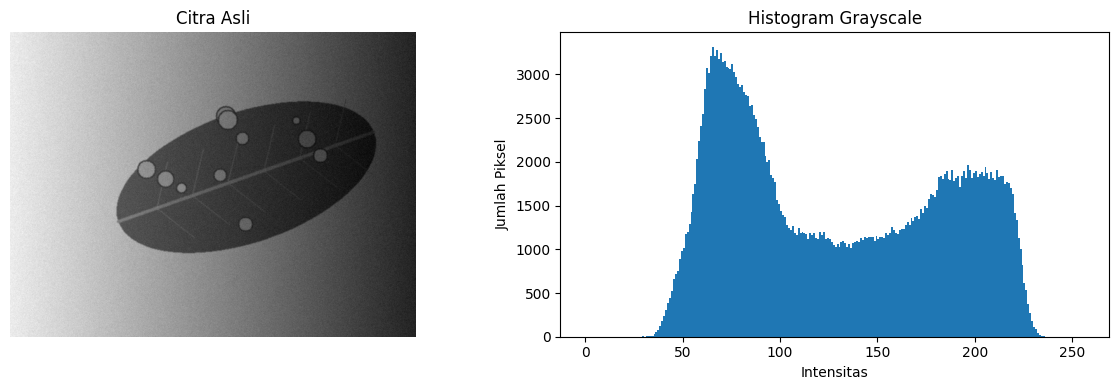

In [3]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Histogram Grayscale")
plt.xlabel("Intensitas")
plt.ylabel("Jumlah Piksel")

plt.tight_layout()
plt.savefig(os.path.join(HASIL, "b3_histogram_asli.png"), dpi=200)
plt.show()

In [4]:
def negative(img):
    return 255 - img


def brightness(img, beta=50):
    return cv2.convertScaleAbs(img, alpha=1, beta=beta)


def contrast(img, alpha=1.5, beta=-40):
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def contrast_stretch(img):
    p2, p98 = np.percentile(img, (2, 98))

    if p98 == p2:
        return img.copy()

    hasil = (img.astype(np.float32) - p2) * (
        255 / (p98 - p2)
    )

    return np.clip(hasil, 0, 255).astype(np.uint8)


def gamma_correction(img, gamma):
    tabel = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in range(256)
    ]).astype(np.uint8)

    return cv2.LUT(img, tabel)


def histogram_equalization(img):
    return cv2.equalizeHist(img)


def clahe_gray(img, clip=2.0, tile=8):
    clahe = cv2.createCLAHE(
        clipLimit=clip,
        tileGridSize=(tile, tile)
    )

    return clahe.apply(img)

Asli


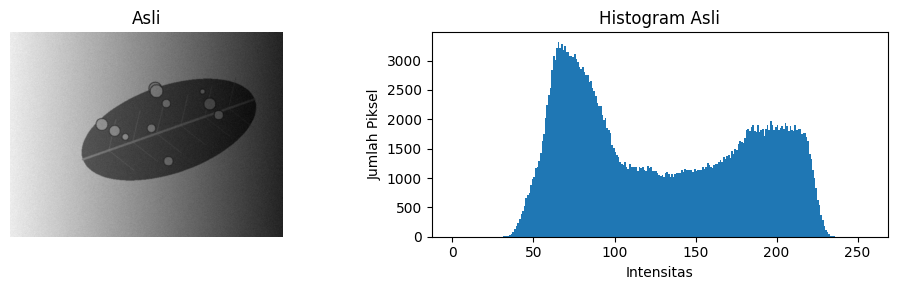

Negative


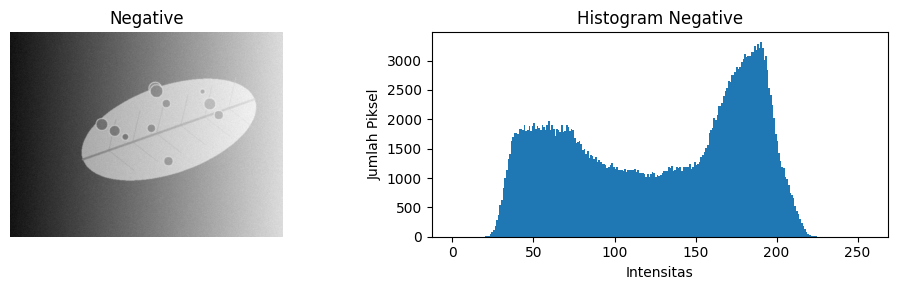

Brightness +50


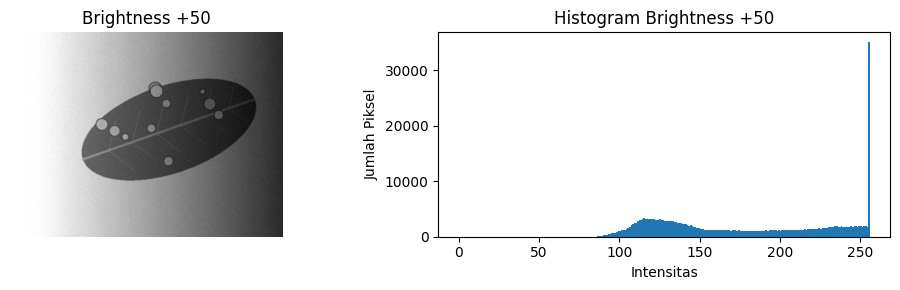

Contrast


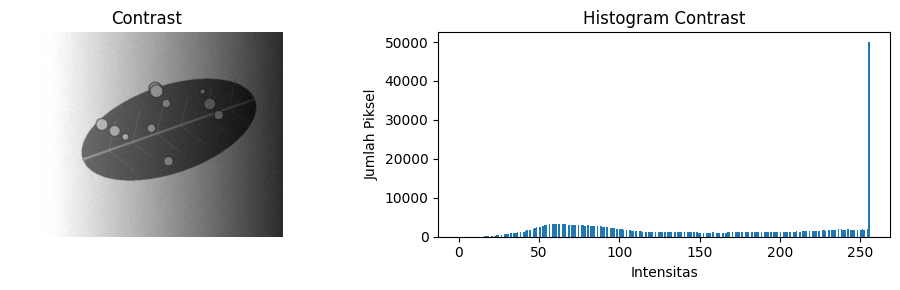

Stretching


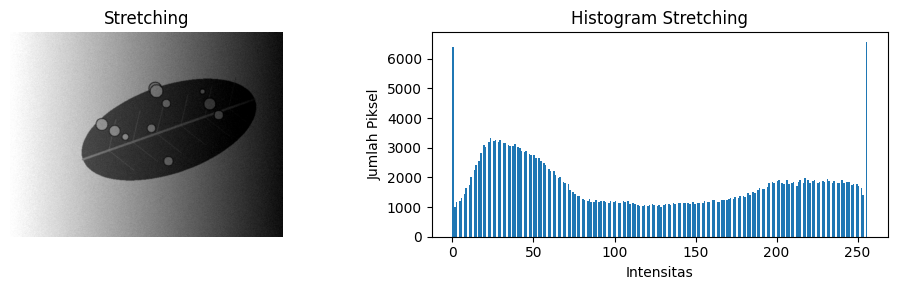

Gamma 0.5


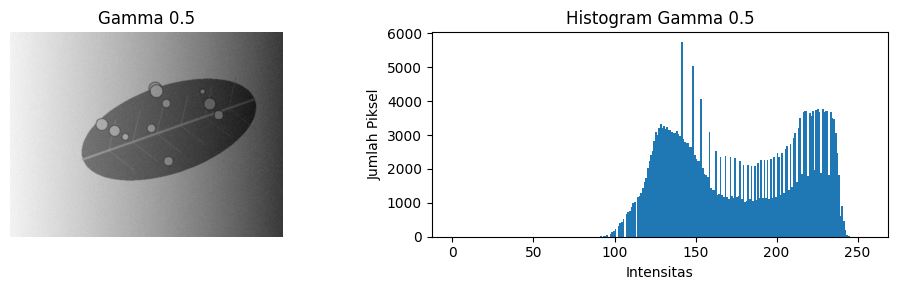

Gamma 1.8


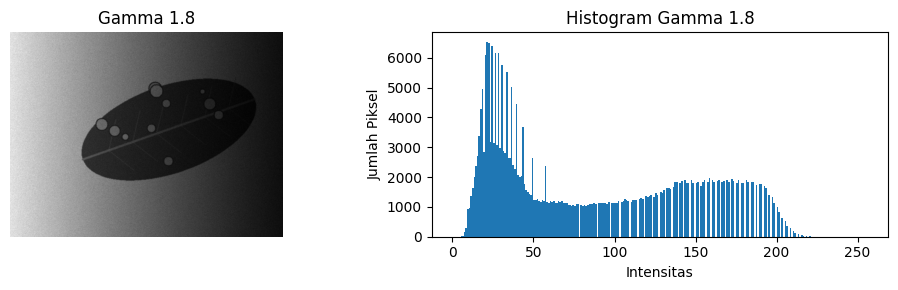

Equalization


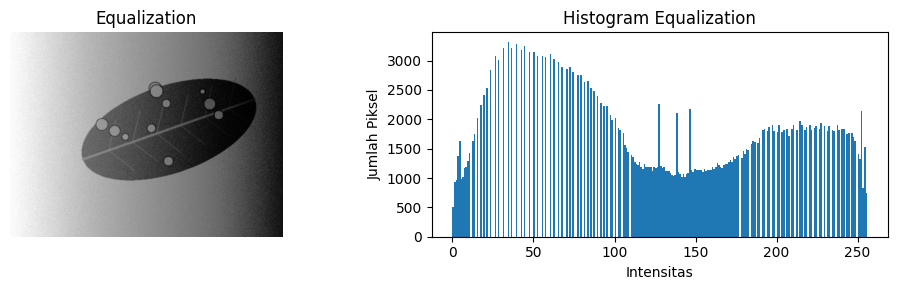

CLAHE


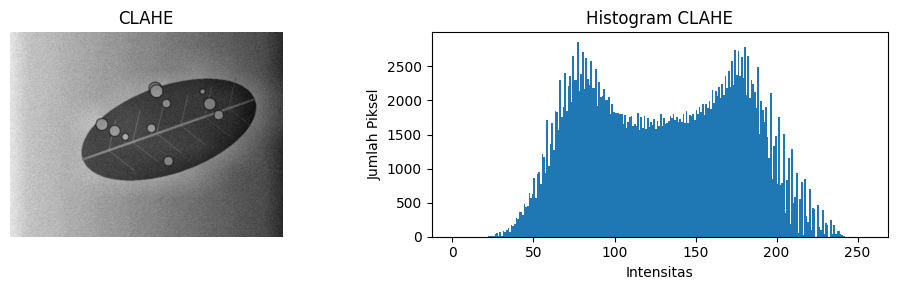

In [5]:
hasil_dasar = [
    ("Asli", gray),
    ("Negative", negative(gray)),
    ("Brightness +50", brightness(gray, 50)),
    ("Contrast", contrast(gray, 1.5, -40)),
    ("Stretching", contrast_stretch(gray)),
    ("Gamma 0.5", gamma_correction(gray, 0.5)),
    ("Gamma 1.8", gamma_correction(gray, 1.8)),
    ("Equalization", histogram_equalization(gray)),
    ("CLAHE", clahe_gray(gray))
]

for nama_metode, hasil in hasil_dasar:
    print(nama_metode)

    plt.figure(figsize=(10, 3))

    plt.subplot(1, 2, 1)
    plt.imshow(hasil, cmap="gray")
    plt.title(nama_metode)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.hist(hasil.ravel(), bins=256, range=(0, 256))
    plt.title("Histogram " + nama_metode)
    plt.xlabel("Intensitas")
    plt.ylabel("Jumlah Piksel")

    plt.tight_layout()
    plt.show()

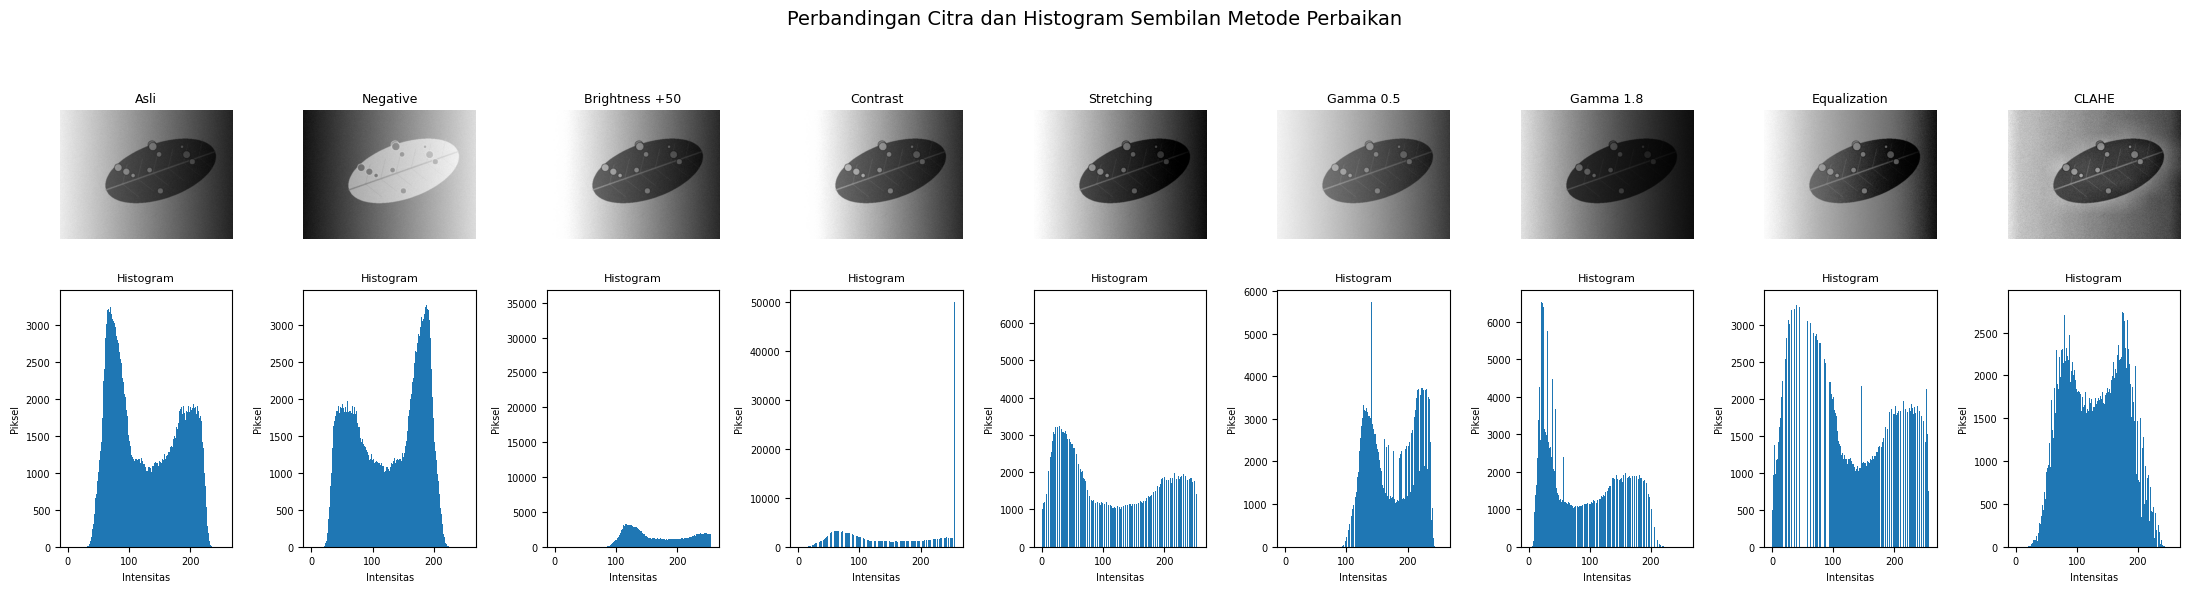

In [6]:
fig, axes = plt.subplots(2, 9, figsize=(22, 6))

for i, (nama_metode, hasil) in enumerate(hasil_dasar):

    # Baris pertama: citra
    axes[0, i].imshow(hasil, cmap="gray")
    axes[0, i].set_title(nama_metode, fontsize=9)
    axes[0, i].axis("off")

    # Baris kedua: histogram
    axes[1, i].hist(
        hasil.ravel(),
        bins=256,
        range=(0, 256)
    )

    axes[1, i].set_title("Histogram", fontsize=8)
    axes[1, i].set_xlabel("Intensitas", fontsize=7)
    axes[1, i].set_ylabel("Piksel", fontsize=7)
    axes[1, i].tick_params(labelsize=7)

plt.suptitle(
    "Perbandingan Citra dan Histogram Sembilan Metode Perbaikan",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b3_perbandingan_9_metode.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
md = cv2.imread(
    os.path.join(MASK_DAUN, "teh_045.png"),
    cv2.IMREAD_GRAYSCALE
)

mb = cv2.imread(
    os.path.join(MASK_BERCAK, "teh_045.png"),
    cv2.IMREAD_GRAYSCALE
)

if md is None or mb is None:
    raise FileNotFoundError("Mask daun atau mask bercak tidak ditemukan.")


def hitung_kb(img, mask_daun, mask_bercak):

    daun = mask_daun > 0
    bercak = (mask_bercak > 0) & daun
    sehat = daun & (mask_bercak == 0)

    if not np.any(bercak) or not np.any(sehat):
        return np.nan

    rata_bercak = np.mean(img[bercak])
    rata_sehat = np.mean(img[sehat])
    std_sehat = np.std(img[sehat])

    if std_sehat == 0:
        return np.nan

    return abs(rata_bercak - rata_sehat) / std_sehat

In [8]:
hasil_statistik = []

for nama_metode, hasil in hasil_dasar:

    kb = hitung_kb(hasil, md, mb)
    std = np.std(hasil)

    hasil_statistik.append({
        "Metode": nama_metode,
        "KB": kb,
        "Standar Deviasi": std,
        "Mean": np.mean(hasil),
        "Minimum": np.min(hasil),
        "Maksimum": np.max(hasil)
    })

tabel_b3 = pd.DataFrame(hasil_statistik)

print(tabel_b3.round(2))

tabel_b3.to_csv(
    os.path.join(HASIL, "b3_statistik_9_metode.csv"),
    index=False
)

           Metode    KB  Standar Deviasi    Mean  Minimum  Maksimum
0            Asli  1.86            55.32  128.44       29       239
1        Negative  1.86            55.32  126.56       16       226
2  Brightness +50  1.86            53.66  177.36       79       255
3        Contrast  1.86            78.11  149.33        4       255
4      Stretching  1.91            81.70  117.32        0       255
5       Gamma 0.5  1.62            39.73  176.03       85       246
6       Gamma 1.8  2.29            59.65   83.60        5       226
7    Equalization  1.40            73.48  128.33        0       255
8           CLAHE  2.45            47.18  130.04       21       244


In [11]:
daftar_diagnosis = [
    "teh_041.png",
    "teh_042.png",
    "teh_043.png",
    "teh_044.png",
    "teh_045.png",
    "teh_021.png",
    "teh_022.png",
    "teh_023.png",
    "teh_024.png",
    "teh_025.png"
]

diagnosis = []

for nama_file in daftar_diagnosis:

    img_uji = baca(os.path.join(CITRA, nama_file))
    gray_uji = cv2.cvtColor(img_uji, cv2.COLOR_BGR2GRAY)

    stats = statistik(gray_uji)

    diagnosis.append({
        "Nama File": nama_file,
        "Mean": stats["mean"],
        "Standar Deviasi": stats["std"],
        "Minimum": stats["min"],
        "Maksimum": stats["max"],
        "Persen Gelap": stats["dark_pct"],
        "Persen Terang": stats["bright_pct"]
    })

tabel_diagnosis = pd.DataFrame(diagnosis)

print(tabel_diagnosis.round(2))

tabel_diagnosis.to_csv(
    os.path.join(HASIL, "b3_diagnosis_pencahayaan.csv"),
    index=False
)

     Nama File   Mean  Standar Deviasi  Minimum  Maksimum  Persen Gelap  \
0  teh_041.png  172.2             46.7       67       228           0.0   
1  teh_042.png  129.0             44.4       14       182           6.8   
2  teh_043.png  209.7             25.1      128       254           0.0   
3  teh_044.png  153.4             13.8       96       198           0.0   
4  teh_045.png  128.4             55.3       29       239           2.1   
5  teh_021.png  182.4             44.5       63       244           0.0   
6  teh_022.png  118.7             35.5       14       176           8.9   
7  teh_023.png  212.9             25.6      147       249           0.0   
8  teh_024.png  155.1             15.2       92       203           0.0   
9  teh_025.png  126.4             59.2       20       252           2.6   

   Persen Terang  
0           16.5  
1            0.0  
2           76.4  
3            0.0  
4           10.8  
5           38.8  
6            0.0  
7           77.2  
8  

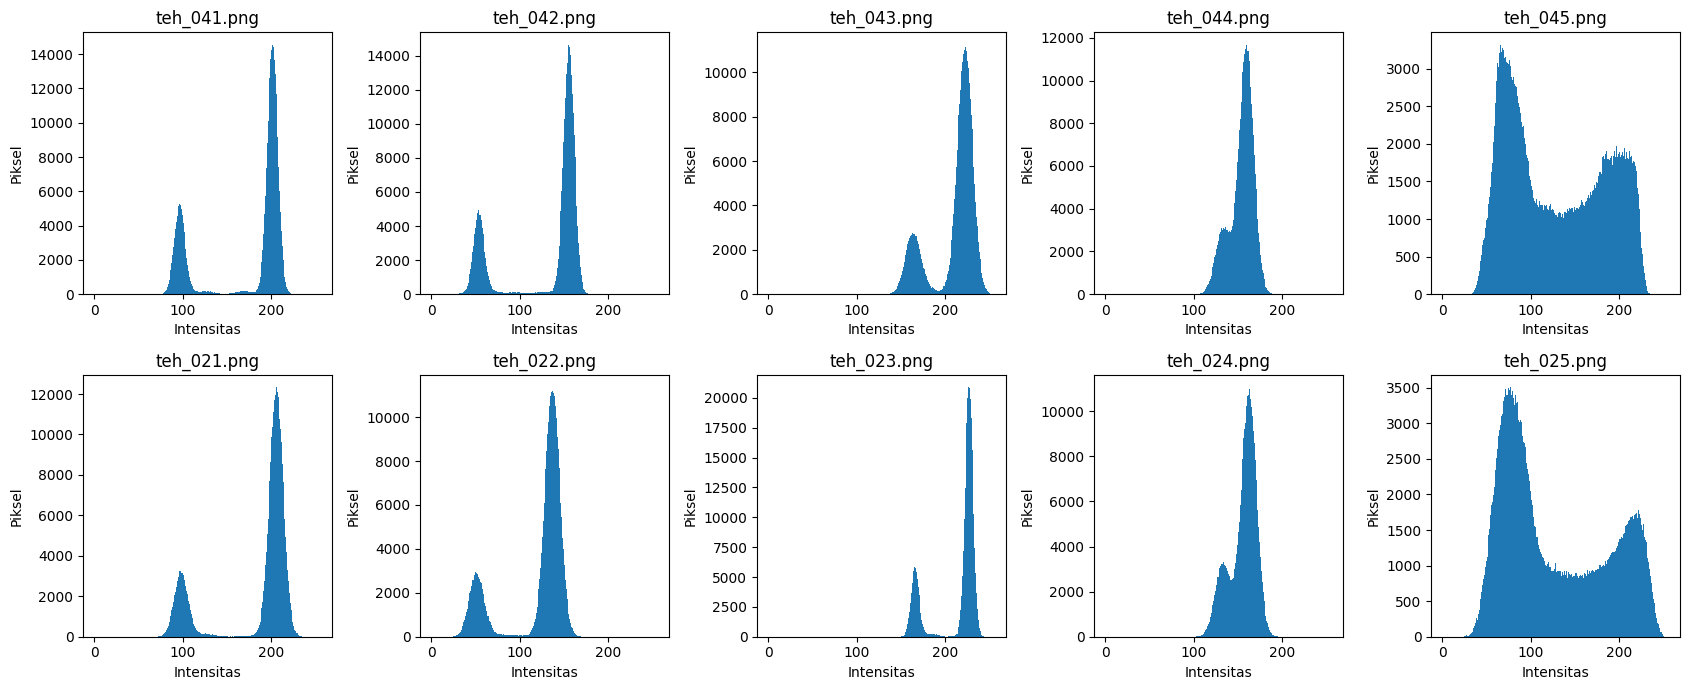

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))

for i, nama_file in enumerate(daftar_diagnosis):

    img_uji = baca(os.path.join(CITRA, nama_file))
    gray_uji = cv2.cvtColor(img_uji, cv2.COLOR_BGR2GRAY)

    ax = axes[i // 5, i % 5]

    ax.hist(
        gray_uji.ravel(),
        bins=256,
        range=(0, 256)
    )

    ax.set_title(nama_file)
    ax.set_xlabel("Intensitas")
    ax.set_ylabel("Piksel")

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b3_histogram_diagnosis.png"),
    dpi=250
)

plt.show()

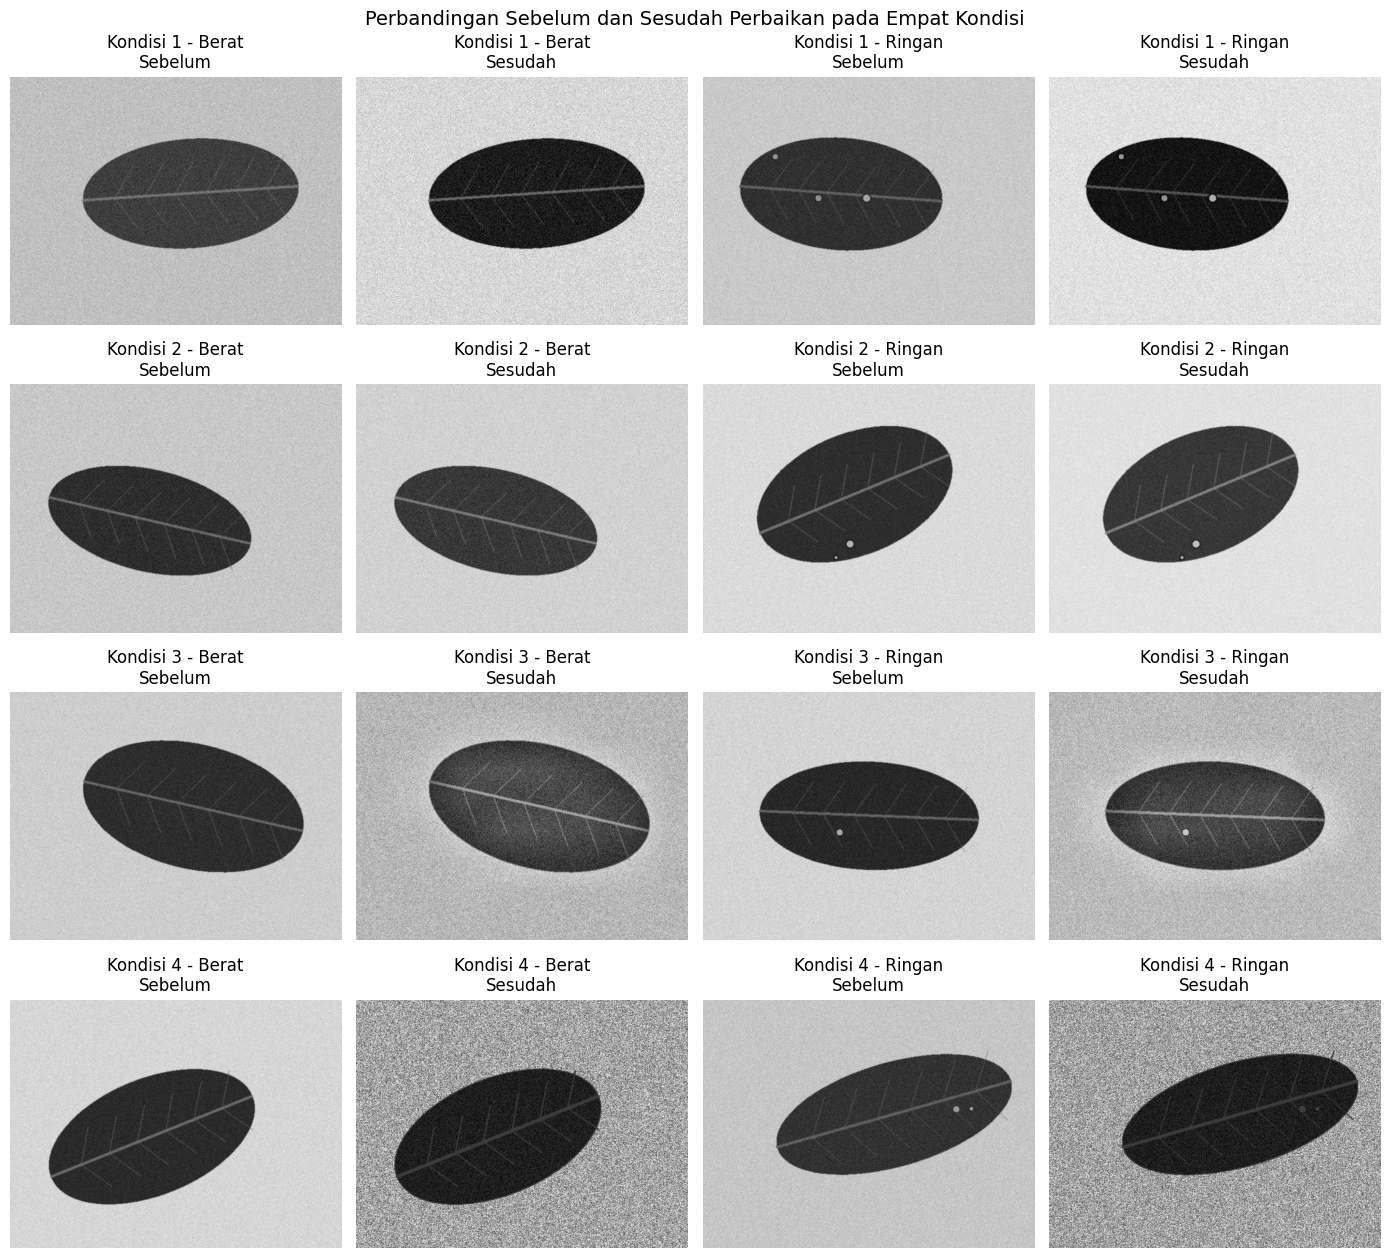

In [17]:

# Empat kondisi pencahayaan
# Ganti nama file sesuai hasil diagnosis dan label.csv

daftar_uji = [
    ("Kondisi 1", "teh_001.png", "teh_021.png", "stretching"),
    ("Kondisi 2", "teh_006.png", "teh_026.png", "gamma"),
    ("Kondisi 3", "teh_011.png", "teh_031.png", "clahe"),
    ("Kondisi 4", "teh_016.png", "teh_036.png", "equalization")
]

fig, axes = plt.subplots(4, 4, figsize=(14, 13))

for i, (kondisi, file_berat, file_ringan, metode) in enumerate(daftar_uji):

    for j, nama_file in enumerate([file_berat, file_ringan]):

        citra = baca(os.path.join(CITRA, nama_file))
        gray_uji = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)

        hasil = pilih_perbaikan(gray_uji, metode)

        # Sebelum
        axes[i, j*2].imshow(gray_uji, cmap="gray")
        axes[i, j*2].set_title(
            f"{kondisi} - {'Berat' if j == 0 else 'Ringan'}\nSebelum"
        )
        axes[i, j*2].axis("off")

        # Sesudah
        axes[i, j*2+1].imshow(hasil, cmap="gray")
        axes[i, j*2+1].set_title(
            f"{kondisi} - {'Berat' if j == 0 else 'Ringan'}\nSesudah"
        )
        axes[i, j*2+1].axis("off")

plt.suptitle(
    "Perbandingan Sebelum dan Sesudah Perbaikan pada Empat Kondisi",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b3_sebelum_sesudah_4_kondisi.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:
kombinasi_clahe = [
    (1.0, 4),
    (1.0, 8),
    (1.0, 16),
    (2.0, 4),
    (2.0, 8),
    (2.0, 16),
    (4.0, 4),
    (4.0, 8),
    (4.0, 16)
]

hasil_clahe = []

for clip, tile in kombinasi_clahe:

    hasil = clahe_gray(gray, clip, tile)

    kb = hitung_kb(hasil, md, mb)

    hasil_clahe.append({
        "Clip Limit": clip,
        "Tile": tile,
        "KB": kb,
        "Standar Deviasi": np.std(hasil)
    })

tabel_clahe = pd.DataFrame(hasil_clahe)

print(tabel_clahe.round(2))

tabel_clahe.to_csv(
    os.path.join(HASIL, "b3_pengujian_clahe.csv"),
    index=False
)

   Clip Limit  Tile    KB  Standar Deviasi
0         1.0     4  2.57            50.82
1         1.0     8  2.53            50.44
2         1.0    16  2.46            51.25
3         2.0     4  2.47            47.74
4         2.0     8  2.45            47.18
5         2.0    16  2.46            49.60
6         4.0     4  2.00            46.00
7         4.0     8  1.94            42.87
8         4.0    16  2.07            43.33


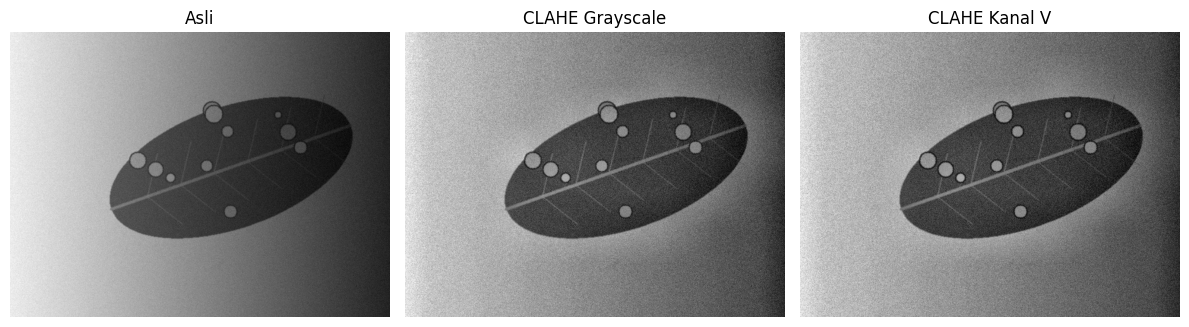

KB CLAHE grayscale: 2.451335453212904
KB CLAHE kanal V: 2.469855338442733


In [14]:
# CLAHE grayscale
clahe_gray_result = clahe_gray(gray, 2.0, 8)

# CLAHE kanal V
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(hsv)

clahe_v = clahe_gray(v, 2.0, 8)

hasil_hsv = cv2.merge([h, s, clahe_v])

clahe_v_result = cv2.cvtColor(
    hasil_hsv,
    cv2.COLOR_HSV2BGR
)

clahe_v_gray = cv2.cvtColor(
    clahe_v_result,
    cv2.COLOR_BGR2GRAY
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Asli")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(clahe_gray_result, cmap="gray")
plt.title("CLAHE Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_v_gray, cmap="gray")
plt.title("CLAHE Kanal V")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b3_clahe_perbandingan.png"),
    dpi=250
)

plt.show()

print("KB CLAHE grayscale:",
      hitung_kb(clahe_gray_result, md, mb))

print("KB CLAHE kanal V:",
      hitung_kb(clahe_v_gray, md, mb))

In [15]:
# Contoh pemetaan awal.
# Sesuaikan setelah melihat hasil diagnosis dan tabel KB.

metode_kondisi = {
    "normal": "asli",
    "gelap": "gamma",
    "terang": "asli",
    "kontras rendah": "clahe",
    "bayangan": "clahe"
}


def pilih_perbaikan(gray, metode):

    if metode == "asli":
        return gray.copy()

    elif metode == "gamma":
        return gamma_correction(gray, 0.5)

    elif metode == "stretching":
        return contrast_stretch(gray)

    elif metode == "equalization":
        return histogram_equalization(gray)

    elif metode == "clahe":
        return clahe_gray(gray, 2.0, 8)

    elif metode == "negative":
        return negative(gray)

    else:
        raise ValueError("Metode tidak dikenal")

In [16]:
# Simpan tabel hasil pengujian
tabel_b3.to_csv(
    os.path.join(HASIL, "b3_statistik_9_metode.csv"),
    index=False
)

tabel_diagnosis.to_csv(
    os.path.join(HASIL, "b3_diagnosis_pencahayaan.csv"),
    index=False
)

tabel_clahe.to_csv(
    os.path.join(HASIL, "b3_pengujian_clahe.csv"),
    index=False
)

print("Pengujian B3 selesai.")
print("Lokasi hasil:", HASIL)

Pengujian B3 selesai.
Lokasi hasil: /content/drive/MyDrive/simuteh-1004/hasil
